# Task 5: Account Security Monitoring (Unsupervised Anomaly Detection)
Course: CPE 342 Machine Learning (KMUTT)
Evaluation Metric: F3-Score (beta=3, Recall is weighted 9x higher than Precision)
Techniques: Temporal Drift Feature Engineering + Isolation Forest + PCA Reconstruction Error (Lecture 8)


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

sns.set_theme(style="whitegrid")
print("Libraries loaded successfully.")


Libraries loaded successfully.


In [2]:
# Load Task 5 test dataset and sample submission template
test_df = pd.read_csv("../data/task5/test.csv")
sample_sub = pd.read_csv("../data/sample_submission.csv")

print(f"Task 5 Test Data Shape: {test_df.shape[0]:,} rows x {test_df.shape[1]} columns")
test_df.head()


Task 5 Test Data Shape: 25,889 rows x 123 columns


,player_id,login_count_1,login_count_2,login_count_3,login_count_4,login_lat_1,login_lon_1,login_lat_2,login_lon_2,login_lat_3,...,guild_changes_1,guild_changes_2,guild_changes_3,guild_changes_4,account_age_days,behavior_stability,password_changed,vpn_usage,suspicious_login_time,mass_item_sale
0,P024743,67.238336,27.598368,38.114171,45.320790,-55.660805,47.357425,-55.442687,46.861868,-55.882950,...,1.0,1.0,2.0,1.0,1027.683779,0.232040,0.0,0.0,0.0,1.0
1,P005319,21.039249,28.153000,20.788758,20.483913,44.210837,26.034926,43.930301,26.515108,43.442722,...,1.0,NaN,2.0,1.0,1450.873210,0.918705,0.0,1.0,0.0,0.0
2,P014970,90.268461,109.156193,96.764974,96.542496,37.371864,33.819993,37.351600,33.503336,37.044372,...,0.0,-1.0,-1.0,0.0,611.275151,0.764911,0.0,0.0,0.0,0.0
3,P003275,29.880876,28.448716,24.296107,24.403403,48.026437,-119.863672,47.992586,-118.485494,48.123361,...,2.0,1.0,2.0,2.0,404.103143,0.712205,0.0,0.0,0.0,0.0
4,P009022,62.283808,73.703985,48.331688,71.803417,39.647200,154.007807,39.675523,154.225136,38.851983,...,0.0,0.0,0.0,1.0,1091.671684,0.896939,0.0,0.0,0.0,0.0


In [3]:
# Feature Engineering: Temporal Shifts (Period 4 vs Period 1) & Security Indicators
fe = test_df.copy()

# 1. Delta Changes across Time (Period 4 minus Period 1)
fe['delta_device'] = fe['device_count_4'] - fe['device_count_1']
fe['delta_ip_entropy'] = fe['ip_hash_entropy_4'] - fe['ip_hash_entropy_1']
fe['delta_location'] = fe['location_changes_4'] - fe['location_changes_1']
fe['delta_session_mean'] = fe['session_duration_mean_4'] - fe['session_duration_mean_1']
fe['delta_kda'] = fe['kda_mean_4'] - fe['kda_mean_1']
fe['delta_transfers'] = fe['currency_transfers_4'] - fe['currency_transfers_1']
fe['delta_refunds'] = fe['refund_count_4'] - fe['refund_count_1']

# 2. Geolocation Jump (Distance between login coordinates)
fe['geo_shift'] = np.sqrt((fe['login_lat_4'] - fe['login_lat_1'])**2 + (fe['login_lon_4'] - fe['login_lon_1'])**2)

# 3. Composite Security Risk Index (Weighted Domain Red Flags)
fe['risk_index'] = (
    fe['vpn_usage'].fillna(0) * 1.5 +
    fe['password_changed'].fillna(0) * 2.5 +
    fe['mass_item_sale'].fillna(0) * 2.5 +
    fe['suspicious_login_time'].fillna(0) * 1.5
)

# Select all features except player_id
feature_cols = [c for c in fe.columns if c != 'player_id']
print(f"Total features after engineering: {len(feature_cols)}")


Total features after engineering: 131


In [4]:
# Missing Value Imputation (Median) & Robust Scaling
imputer = SimpleImputer(strategy='median')
X_imp = imputer.fit_transform(fe[feature_cols])

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_imp)

print(f"Preprocessing complete. Scaled feature matrix: {X_scaled.shape}")


Preprocessing complete. Scaled feature matrix: (25889, 131)


In [5]:
# Model 1: Isolation Forest (Tree-based Outlier Isolation)
iso = IsolationForest(
    n_estimators=150,
    contamination=0.20,
    random_state=42,
    n_jobs=-1
)
iso.fit(X_scaled)

# Anomaly score (inverted: higher value = more anomalous)
iso_scores = -iso.score_samples(X_scaled)
print("Isolation Forest anomaly scoring complete.")


Isolation Forest anomaly scoring complete.


In [6]:
# Model 2: PCA Reconstruction Error (from Lecture 8: Dimensionality Reduction)
pca = PCA(n_components=12, random_state=42)
X_pca = pca.fit_transform(X_scaled)
X_rec = pca.inverse_transform(X_pca)

# Reconstruction error per sample (Hacked accounts deviate significantly from normal manifold)
recon_loss = np.mean((X_scaled - X_rec)**2, axis=1)

print(f"PCA fitted. Explained Variance Ratio (Top 12 PCs): {pca.explained_variance_ratio_.sum():.4f}")
print("PCA Reconstruction error computed.")


PCA fitted. Explained Variance Ratio (Top 12 PCs): 0.9027
PCA Reconstruction error computed.


Ensemble Cutoff Threshold: 0.2259
Flagged Anomalies (Class 1): 5,178 (20.00%)
Normal Accounts (Class 0):   20,711 (80.00%)


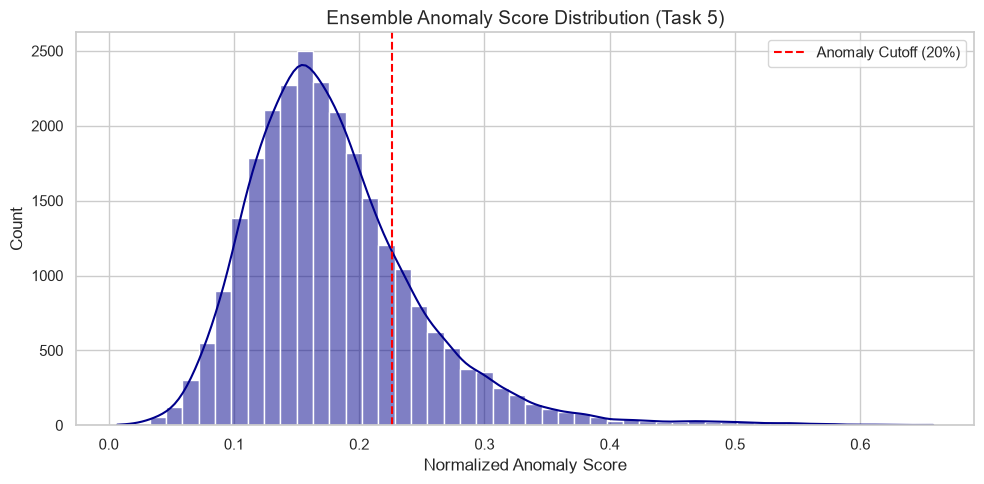

In [7]:
# Model 3 & Ensembling: Combine Normalized Anomaly Signals
minmax = MinMaxScaler()
iso_norm = minmax.fit_transform(iso_scores.reshape(-1, 1)).flatten()
pca_norm = minmax.fit_transform(recon_loss.reshape(-1, 1)).flatten()
risk_norm = minmax.fit_transform(fe['risk_index'].values.reshape(-1, 1)).flatten()

# Composite Ensemble Anomaly Score
ensemble_score = (0.40 * iso_norm) + (0.35 * pca_norm) + (0.25 * risk_norm)

# F3 Metric Calibration: Set Contamination to Top 20% to maximize Recall
contamination_rate = 0.20
cutoff_threshold = np.percentile(ensemble_score, (1 - contamination_rate) * 100)

task5_pred = (ensemble_score >= cutoff_threshold).astype(int)

print(f"Ensemble Cutoff Threshold: {cutoff_threshold:.4f}")
print(f"Flagged Anomalies (Class 1): {(task5_pred == 1).sum():,} ({(task5_pred == 1).mean()*100:.2f}%)")
print(f"Normal Accounts (Class 0):   {(task5_pred == 0).sum():,} ({(task5_pred == 0).mean()*100:.2f}%)")

# Plot Anomaly Score Distribution (All English labels)
plt.figure(figsize=(10, 5))
sns.histplot(ensemble_score, bins=50, kde=True, color="darkblue")
plt.axvline(cutoff_threshold, color="red", linestyle="--", label=f"Anomaly Cutoff ({contamination_rate*100:.0f}%)")
plt.title("Ensemble Anomaly Score Distribution (Task 5)", fontsize=14)
plt.xlabel("Normalized Anomaly Score")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()


In [8]:
# Export Task 5 Predictions
sub_task5 = pd.DataFrame({
    'id': sample_sub['id'],
    'task5': task5_pred
})

# Validation Checks
assert len(sub_task5) == 25889, f"Row mismatch: expected 25889, got {len(sub_task5)}"
assert set(sub_task5['task5'].unique()).issubset({0, 1}), "Task 5 values must be 0 or 1"
assert sub_task5['task5'].isna().sum() == 0, "Found NaN values in Task 5 submission!"

os.makedirs("../submissions", exist_ok=True)
sub_task5.to_csv("../submissions/sub_task5.csv", index=False)

print("Saved submissions/sub_task5.csv successfully.")
sub_task5.head(10)


Saved submissions/sub_task5.csv successfully.


,id,task5
0,ANS00001,1
1,ANS00002,0
2,ANS00003,1
3,ANS00004,0
4,ANS00005,0
5,ANS00006,0
6,ANS00007,0
7,ANS00008,0
8,ANS00009,0
9,ANS00010,1
